# 01 - Selection (KDD stage 1) - real data
**Disaster Early Warning project - machine learning on the two real weather files in this repo.**

This notebook series (01-05) is the *real-data* counterpart of the synthetic pipeline in
`backend/notebooks`. Every number below is computed from the two Excel files in the repo root:

| File | Source | Location | Period |
|---|---|---|---|
| `durban_kzn_daily_2021-2022.xlsx` | Open-Meteo Historical Weather API (reanalysis) | Durban, KwaZulu-Natal | 2021-06-01 to 2022-06-30 |
| `mbombela_mpumalanga_daily_2021-2022.csv.xlsx` | Open-Meteo Historical Weather API (reanalysis) | Mbombela, Mpumalanga | 2021-06-01 to 2022-06-30 |

**What this data is not:** it holds daily weather only. There are no river levels, no satellite tiles and
no recorded flood events in these files, so the CNN-LSTM in the backend cannot be trained on it.
Notebook 03 therefore builds a rainfall-hazard target from the data itself and says so openly.

In [1]:
import sys
from pathlib import Path


def _find_helpers():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base, base / "notebooks" / "real_data"):
            if (cand / "weather_data.py").is_file():
                return cand
    raise SystemExit("weather_data.py not found. Open this notebook from inside the repository.")


sys.path.insert(0, str(_find_helpers()))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import weather_data as wd

ROOT = wd.find_root()
OUT = wd.out_dir(ROOT)
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
COLORS = {"KZN-ETHEKWINI": "#2a6fbb", "MP-EHLANZENI": "#d9822b"}
LABEL = {rid: s["label"] for rid, s in wd.STATIONS.items()}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("repo root:", ROOT)

repo root: /home/claude/karaboitumeleng/disaster-early-warning-project


## 1. Load the files
The Excel sheets store the CSV text in one column (a metadata block, a blank line, then the table).
`weather_data.load_station` parses that layout and raises an error if it is not what it expects.

In [2]:
df, meta = wd.load_all(ROOT)
pd.DataFrame(meta).T[["label", "lat", "lon", "elevation_m", "file"]]

,label,lat,lon,elevation_m,file
KZN-ETHEKWINI,Durban (KwaZulu-Natal),-29.841827,30.976744,9.0,durban_kzn_daily_2021-2022.xlsx
MP-EHLANZENI,Mbombela (Mpumalanga),-25.413006,31.007584,660.0,mbombela_mpumalanga_daily_2021-2022.csv.xlsx


In [3]:
df.head()

,region_id,date,rainfall_mm,temperature_c,humidity_pct,pressure_hpa,wind_kmh
0,KZN-ETHEKWINI,2021-06-01,2.6,16.3,63,1018.2,28.7
1,KZN-ETHEKWINI,2021-06-02,31.3,16.3,75,1019.3,30.1
2,KZN-ETHEKWINI,2021-06-03,19.9,15.3,85,1026.5,35.8
3,KZN-ETHEKWINI,2021-06-04,1.2,15.2,71,1029.4,24.2
4,KZN-ETHEKWINI,2021-06-05,0.0,16.1,65,1030.3,14.8


## 2. Coverage and integrity checks

In [4]:
rows = []
for rid, g in df.groupby("region_id"):
    expected = pd.date_range(g["date"].min(), g["date"].max(), freq="D")
    rows.append({
        "region": LABEL[rid], "rows": len(g), "first_day": g["date"].min().date(),
        "last_day": g["date"].max().date(), "calendar_days_expected": len(expected),
        "missing_days": len(expected.difference(g["date"])), "duplicate_days": int(g["date"].duplicated().sum()),
        "missing_values": int(g.isna().sum().sum()),
    })
pd.DataFrame(rows)

,region,rows,first_day,last_day,calendar_days_expected,missing_days,duplicate_days,missing_values
0,Durban (KwaZulu-Natal),395,2021-06-01,2022-06-30,395,0,0,0
1,Mbombela (Mpumalanga),395,2021-06-01,2022-06-30,395,0,0,0


Both files cover 395 consecutive days with no gaps and no missing values. (`Dataset_README.md` says
399 days; that figure appears to count the four header lines of each file. The rows are the truth.)

## 3. First look at the variables

In [5]:
summary = df.groupby("region_id")[["rainfall_mm", "temperature_c", "humidity_pct", "pressure_hpa", "wind_kmh"]] \
    .describe().T.round(2)
summary

region_id            KZN-ETHEKWINI  MP-EHLANZENI
rainfall_mm   count         395.00        395.00
              mean            3.33          2.49
              std            10.67          5.49
              min             0.00          0.00
              25%             0.00          0.00
              50%             0.10          0.20
              75%             1.70          2.60
              max           117.80         51.90
temperature_c count         395.00        395.00
              mean           19.87         18.92
              std             3.39          3.87
              min            11.70          9.30
              25%            17.20         16.05
              50%            19.50         18.90
              75%            22.75         22.50
              max            27.40         27.60
humidity_pct  count         395.00        395.00
              mean           74.47         70.70
              std            10.28         13.72
              min            34.00         28.00
              25%            70.00         64.00
              50%            76.00         74.00
              75%            82.00         81.00
              max            93.00         93.00
pressure_hpa  count         395.00        395.00
              mean         1018.08       1019.37
              std             6.41          5.80
              min          1005.80       1007.10
              25%          1013.40       1015.00
              50%          1017.30       1018.20
              75%          1022.50       1023.45
              max          1037.50       1036.10
wind_kmh      count         395.00        395.00
              mean           21.94         13.23
              std             7.03          2.64
              min             8.80          6.60
              25%            16.15         11.40
              50%            21.40         13.00
              75%            26.00         14.80
              max            47.70         24.00

In [6]:
wet = []
for rid, g in df.groupby("region_id"):
    top = g.nlargest(5, "rainfall_mm")[["date", "rainfall_mm"]].assign(region=LABEL[rid])
    wet.append(top)
wettest = pd.concat(wet, ignore_index=True)
wettest["date"] = wettest["date"].dt.date
wettest

,date,rainfall_mm,region
0,2022-05-21,117.8,Durban (KwaZulu-Natal)
1,2022-04-11,100.7,Durban (KwaZulu-Natal)
2,2022-05-22,93.7,Durban (KwaZulu-Natal)
3,2022-01-12,36.9,Durban (KwaZulu-Natal)
4,2022-02-04,34.8,Durban (KwaZulu-Natal)
5,2022-01-06,51.9,Mbombela (Mpumalanga)
6,2022-05-21,48.2,Mbombela (Mpumalanga)
7,2022-01-12,28.5,Mbombela (Mpumalanga)
8,2021-11-18,27.4,Mbombela (Mpumalanga)
9,2022-05-22,26.2,Mbombela (Mpumalanga)


Durban's wettest day in this file is **2022-05-21 (117.8 mm)**; 2022-04-11 (100.7 mm), the day linked to the
April 2022 KwaZulu-Natal floods, is second, and 2022-05-22 (93.7 mm) is third. `Dataset_README.md` names
2022-04-11 as the wettest day - the data shows a slightly different order.

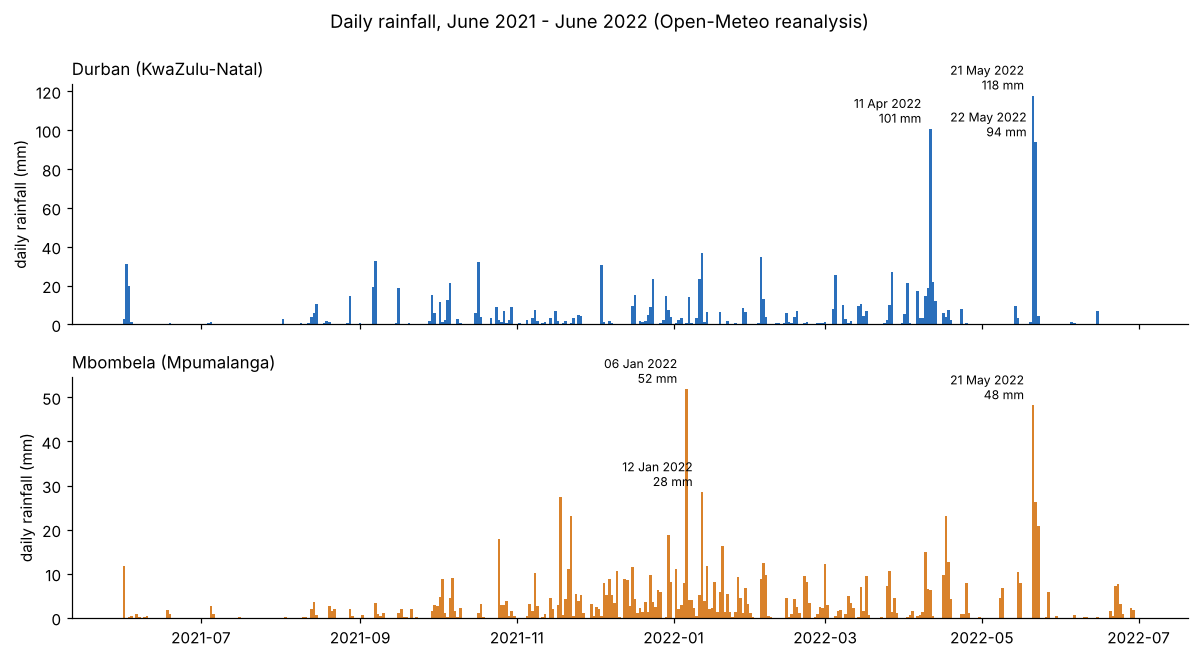

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, (rid, g) in zip(axes, df.groupby("region_id")):
    ax.bar(g["date"], g["rainfall_mm"], width=1.0, color=COLORS[rid])
    top = g.nlargest(3, "rainfall_mm")
    for _, r in top.iterrows():
        ax.annotate(f"{r['date']:%d %b %Y}\n{r['rainfall_mm']:.0f} mm", (r["date"], r["rainfall_mm"]),
                    textcoords="offset points", xytext=(-6, 4), ha="right", fontsize=8)
    ax.set_title(LABEL[rid], loc="left", fontsize=11)
    ax.set_ylabel("daily rainfall (mm)")
fig.suptitle("Daily rainfall, June 2021 - June 2022 (Open-Meteo reanalysis)", y=0.99)
fig.tight_layout()
fig.savefig(FIG / "01_daily_rainfall.png", dpi=130)
plt.show()

region_id,Durban (KwaZulu-Natal),Mbombela (Mpumalanga)
month,,
2021-06,56.2,16.2
2021-07,2.8,3.6
2021-08,45.7,15.1
2021-09,96.7,16.5
2021-10,130.5,68.8
2021-11,46.4,113.8
2021-12,130.8,146.8
2022-01,117.4,206.8
2022-02,77.2,71.9


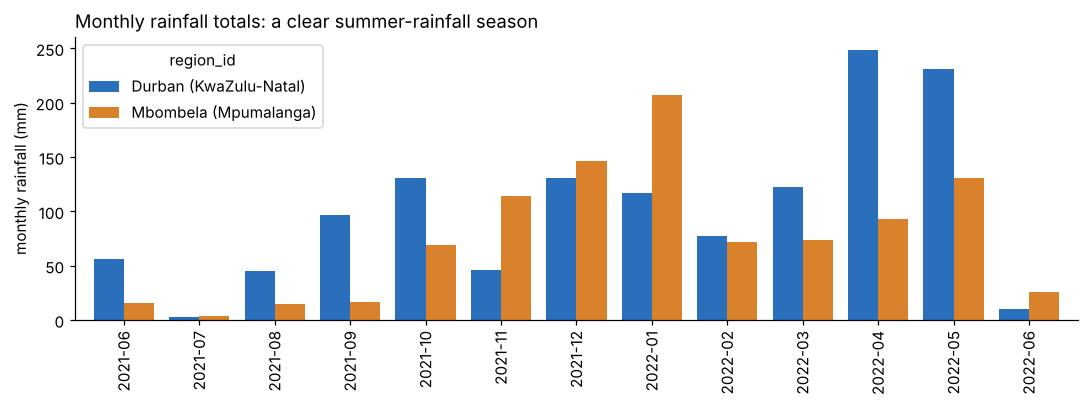

In [8]:
monthly = (df.assign(month=df["date"].dt.to_period("M").astype(str))
             .pivot_table(index="month", columns="region_id", values="rainfall_mm", aggfunc="sum")
             .rename(columns=LABEL).round(1))
ax = monthly.plot(kind="bar", figsize=(10, 3.8), color=[COLORS[r] for r in COLORS], width=0.8)
ax.set_ylabel("monthly rainfall (mm)")
ax.set_xlabel("")
ax.set_title("Monthly rainfall totals: a clear summer-rainfall season", loc="left")
plt.tight_layout()
plt.savefig(FIG / "01_monthly_rainfall.png", dpi=130)
plt.show()
monthly

## 4. Record what was selected (with checksums)
The checksums let a reader confirm later that the notebooks ran on exactly these files.

In [9]:
df.to_csv(OUT / "weather_selected.csv", index=False)
wd_info = {"data_kind": "real", "source": "Open-Meteo Historical Weather API (reanalysis)",
           "rows": int(len(df)), "stations": meta}
(OUT / "weather_selected.meta.json").write_text(json.dumps(wd_info, indent=2, default=str), encoding="utf-8")
print("saved", OUT.relative_to(ROOT) / "weather_selected.csv", df.shape)
{rid: m["sha256"][:16] + "..." for rid, m in meta.items()}

saved notebooks/real_data/outputs/weather_selected.csv (790, 7)


{'KZN-ETHEKWINI': '74180efe940f46ec...', 'MP-EHLANZENI': '14088c2930eaa314...'}